# Q4: Frequency Distribution – Hospital Waiting Time
**Aim:** To build frequency distributions and descriptive statistics of patient waiting times.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("04_Frequency_Waiting_Time.csv")
except FileNotFoundError:
    np.random.seed(42)
    df = pd.DataFrame({
        "Patient_ID": [f"P{i:03d}" for i in range(1, 151)],
        "Department": np.repeat(["Cardiology", "Neurology", "Orthopedics"], 50),
        "Waiting_Time_Minutes": np.concatenate([np.random.normal(45, 12, 50),
                                                np.random.normal(55, 15, 50),
                                                np.random.gamma(4, 10, 50)]).clip(5).round()})
    df.loc[10, "Waiting_Time_Minutes"] = 120
w = "Waiting_Time_Minutes"
g = df.groupby("Department")[w]
df.head()

,Patient_ID,Department,Waiting_Time_Minutes
0,P001,Cardiology,51.0
1,P002,Cardiology,43.0
2,P003,Cardiology,53.0
3,P004,Cardiology,63.0
4,P005,Cardiology,42.0


### 1. Frequency, relative, percentage and cumulative frequency

In [3]:
bins = range(0, int(df[w].max()) + 11, 10)
ft = pd.DataFrame({"Frequency": pd.cut(df[w], bins=bins, right=False).value_counts().sort_index()})
ft["Relative"] = (ft["Frequency"] / ft["Frequency"].sum()).round(3)
ft["Percentage"] = (ft["Relative"] * 100).round(1)
ft["Cumulative"] = ft["Frequency"].cumsum()
ft

,Frequency,Relative,Percentage,Cumulative
Waiting_Time_Minutes,,,,
"[0, 10)",0,0.000,0.0,0
"[10, 20)",7,0.047,4.7,7
"[20, 30)",19,0.127,12.7,26
"[30, 40)",26,0.173,17.3,52
"[40, 50)",39,0.260,26.0,91
"[50, 60)",28,0.187,18.7,119
"[60, 70)",17,0.113,11.3,136
"[70, 80)",11,0.073,7.3,147
"[80, 90)",1,0.007,0.7,148


### 2. Overall mean, median, mode, range, variance, SD, CV

In [4]:
x = df[w]
pd.Series({"Mean": x.mean(), "Median": x.median(), "Mode": x.mode()[0], "Range": x.max() - x.min(),
           "Variance": x.var(), "Std": x.std(), "CV_%": x.std() / x.mean() * 100}).round(2)

,0
Mean,46.32
Median,45.50
Mode,38.00
Range,109.00
Variance,303.33
Std,17.42
CV_%,37.60


### 3. Department-wise statistics

In [5]:
d = g.agg(["count", "mean", "median", "std", "var", "min", "max"])
d["CV_%"] = d["std"] / d["mean"] * 100
d.round(2)

,count,mean,median,std,var,min,max,CV_%
Department,,,,,,,,
Cardiology,50,43.84,42.0,15.76,248.26,21.0,120.0,35.94
Neurology,50,55.14,55.5,13.11,171.80,16.0,78.0,23.77
Orthopedics,50,39.98,38.0,19.38,375.65,11.0,107.0,48.48


### 4. Waiting time > department mean + 1.5 SD

In [6]:
df[df[w] > g.transform("mean") + 1.5 * g.transform("std")]

,Patient_ID,Department,Waiting_Time_Minutes
10,P011,Cardiology,120.0
65,P066,Neurology,75.0
71,P072,Neurology,78.0
73,P074,Neurology,78.0
82,P083,Neurology,77.0
109,P110,Orthopedics,107.0
114,P115,Orthopedics,71.0
121,P122,Orthopedics,75.0
136,P137,Orthopedics,85.0
147,P148,Orthopedics,72.0


### 5. Outliers per department: IQR and Z-score (|Z| > 3)

In [7]:
q1 = g.transform(lambda s: s.quantile(0.25))
q3 = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["IQR_Outlier"] = (df[w] < q1 - 1.5 * iqr) | (df[w] > q3 + 1.5 * iqr)
df["Z"] = ((df[w] - g.transform("mean")) / g.transform("std")).round(2)
df["Z_Outlier"] = df["Z"].abs() > 3
df[df["IQR_Outlier"] | df["Z_Outlier"]]

,Patient_ID,Department,Waiting_Time_Minutes,IQR_Outlier,Z,Z_Outlier
10,P011,Cardiology,120.0,True,4.83,True
74,P075,Neurology,16.0,True,-2.99,False
109,P110,Orthopedics,107.0,True,3.46,True
136,P137,Orthopedics,85.0,True,2.32,False


### 6. Skewness and kurtosis

In [8]:
pd.DataFrame({"Skewness": g.skew(), "Kurtosis": g.apply(pd.Series.kurt)}).round(3)

,Skewness,Kurtosis
Department,,
Cardiology,2.287,10.147
Neurology,-0.507,0.690
Orthopedics,1.129,1.969


Skewness > 0 → right tail (a few very long waits). Kurtosis > 0 → heavier tails than normal.

### 7. Histogram, frequency polygon, boxplot, bar chart

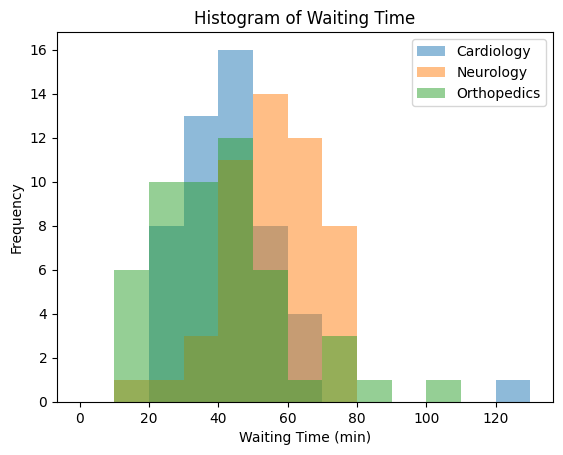

In [9]:
for name, s in g:
    plt.hist(s, bins=bins, alpha=0.5, label=name)
plt.xlabel("Waiting Time (min)")
plt.ylabel("Frequency")
plt.title("Histogram of Waiting Time")
plt.legend()
plt.show()

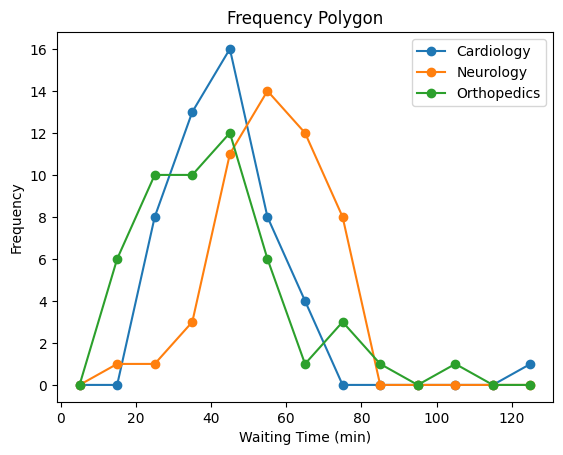

In [10]:
for name, s in g:
    counts, edges = np.histogram(s, bins=bins)
    plt.plot((edges[:-1] + edges[1:]) / 2, counts, marker="o", label=name)
plt.xlabel("Waiting Time (min)")
plt.ylabel("Frequency")
plt.title("Frequency Polygon")
plt.legend()
plt.show()

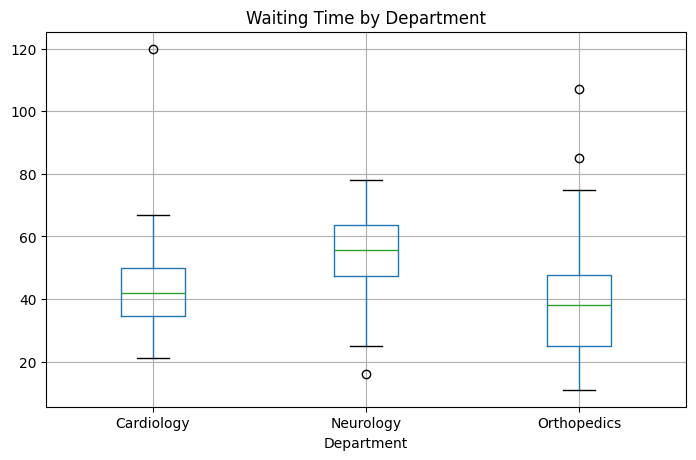

In [11]:
df.boxplot(column=w, by="Department", figsize=(8, 5))
plt.suptitle("")
plt.title("Waiting Time by Department")
plt.show()

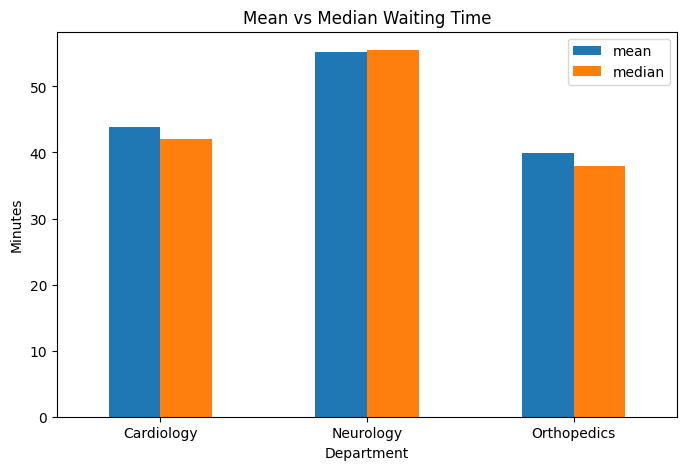

In [12]:
g.agg(["mean", "median"]).plot(kind="bar", figsize=(8, 5))
plt.ylabel("Minutes")
plt.title("Mean vs Median Waiting Time")
plt.xticks(rotation=0)
plt.show()

### 8. % of patients waiting more than 60 minutes

In [13]:
(g.apply(lambda s: (s > 60).mean() * 100)).round(2)

,Waiting_Time_Minutes
Department,
Cardiology,10.0
Neurology,28.0
Orthopedics,12.0


### 9. Mean vs median → skewness check

In [14]:
cmp = g.agg(["mean", "median"])
cmp["Mean - Median"] = cmp["mean"] - cmp["median"]
cmp["Shape"] = np.where(cmp["Mean - Median"] > 1, "Right-skewed",
               np.where(cmp["Mean - Median"] < -1, "Left-skewed", "Roughly symmetric"))
cmp.round(2)

,mean,median,Mean - Median,Shape
Department,,,,
Cardiology,43.84,42.0,1.84,Right-skewed
Neurology,55.14,55.5,-0.36,Roughly symmetric
Orthopedics,39.98,38.0,1.98,Right-skewed


**Result:** Frequency distributions, descriptive statistics, outliers, skewness and kurtosis of waiting times were computed and visualized department-wise.